# The men who were already there

Nine players were at Chelsea for the 10th-place season and the title season. This notebook compares each one's
2015/16 and 2016/17, using official Premier League (Opta) player stats and Understat shot locations.

1. **Player cards.** Two numbers per player that show what changed in his game.
2. **Hazard and Costa shot maps.** Where the two main scorers shot from, in each season.

In [1]:
from pathlib import Path
import html
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
sys.path.insert(0, str(REPO / "src"))
from football_analytics.viz import leaderboard

U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
CHE = "Chelsea"
BLUE, GREY, DARK, MUTED, GOLD = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#FDBE11"
GOLD_TEXT = "#9A7200"  # darker gold for text on white
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def titles(fig, title, subtitle, source):
    """Title above the axes (va=bottom) and subtitle just under it (va=top) so they never overlap."""
    fig.suptitle(title, x=0.01, y=1.06, ha="left", va="bottom", fontsize=14, fontweight="bold", color=DARK)
    fig.text(0.01, 1.055, subtitle, ha="left", va="top", fontsize=10, color=MUTED)
    fig.text(0.01, -0.04, source, ha="left", va="top", fontsize=8, color=MUTED)


def load_shots(season):
    d = pd.read_csv(U / f"shots_epl_{season}.csv")
    d["team"] = np.where(d.h_a == "h", d.h_team, d.a_team)
    d["opp"] = np.where(d.h_a == "h", d.a_team, d.h_team)
    d["goal"] = d.result == "Goal"
    d["date"] = pd.to_datetime(d.date)
    d["player"] = d.player.map(html.unescape)
    return d


def load_players(season):
    p = pd.read_csv(U / f"players_epl_{season}.csv")
    p["player_name"] = p.player_name.map(html.unescape)
    p["team"] = p.team_title.str.split(",").str[-1]  # players who moved mid-season: last club
    return p


def matches(shots):
    """One row per team per match: goals, xG for and against, points."""
    g = shots.groupby("match_id").agg(date=("date", "first"), h=("h_team", "first"), a=("a_team", "first"),
                                      hg=("h_goals", "first"), ag=("a_goals", "first"))
    xg = shots.groupby(["match_id", "team"]).xG.sum()
    rows = []
    for mid, r in g.iterrows():
        for team, opp, gf, ga in [(r.h, r.a, r.hg, r.ag), (r.a, r.h, r.ag, r.hg)]:
            rows.append(dict(match_id=mid, date=r.date, team=team, opp=opp, home=team == r.h, gf=gf, ga=ga,
                             xgf=xg.get((mid, team), 0.0), xga=xg.get((mid, opp), 0.0),
                             pts=3 if gf > ga else 1 if gf == ga else 0))
    m = pd.DataFrame(rows).sort_values(["team", "date"])
    m["n"] = m.groupby("team").cumcount() + 1
    return m


def expected_points(shots, sims=10_000, seed=42):
    """Replay every match `sims` times: each shot is a goal with probability = its xG."""
    rng = np.random.default_rng(seed)
    out = {}
    for mid, g in shots.groupby("match_id"):
        h, a = g.h_team.iloc[0], g.a_team.iloc[0]
        hx, ax = g[g.team == h].xG.values, g[g.team == a].xG.values
        sh = (rng.random((sims, len(hx))) < hx).sum(1)
        sa = (rng.random((sims, len(ax))) < ax).sum(1)
        out[(mid, h)] = (3 * (sh > sa) + (sh == sa)).mean()
        out[(mid, a)] = (3 * (sa > sh) + (sa == sh)).mean()
    return pd.Series(out, name="xpts")

In [2]:
import re

def parse_raw(path):
    """Read premierleague.com stat pages saved as 'key#label|value|label|value...' (English or German number format)."""
    rows = {}
    for line in open(path, encoding="utf-8"):
        key, body = line.strip().split("#", 1)
        parts = body.split("|")
        rec = {}
        for i in range(len(parts) - 1):
            lab, val = parts[i], parts[i + 1]
            if not re.match(r"^[\d.,]+( \(\d+%\))?$", val) or re.match(r"^[\d.,]+( \(\d+%\))?$", lab):
                continue
            num = val.split(" ")[0]
            num = num.replace(".", "").replace(",", "") if re.match(r"^\d{1,3}([.,]\d{3})+$", num) else num.replace(",", ".")
            rec.setdefault(lab, float(num))
            m = re.search(r"\((\d+)%\)", val)
            if m:
                rec.setdefault(lab + " %", float(m.group(1)))
        rows[key] = rec
    return pd.DataFrame(rows).T

P = parse_raw(EXT / "pl_player_raw.txt")
P = P.drop(index=["kante@2015", "kante@2016"])
P["Appearances"] = P.get("Appearances", np.nan).fillna(P.get("Appearances (Sub)"))
P[["Minutes Played", "Goals", "Assists", "XG", "XA", "Passes (Completed %)", "Total Tackles", "Clean Sheets"]].round(2)

,Minutes Played,Goals,Assists,XG,XA,Passes (Completed %),Total Tackles,Clean Sheets
hazard@2015,2190.0,4.0,3.0,2.53,5.57,1415.0,21.0,NaN
hazard@2016,3002.0,16.0,5.0,11.07,9.26,1750.0,18.0,NaN
costa@2015,2379.0,12.0,6.0,12.56,2.52,824.0,21.0,NaN
costa@2016,3089.0,20.0,7.0,14.18,5.49,1034.0,18.0,NaN
azpilicueta@2015,3202.0,2.0,3.0,1.25,2.27,1798.0,114.0,NaN
azpilicueta@2016,3420.0,1.0,4.0,0.63,3.17,2459.0,84.0,NaN
cahill@2015,1955.0,2.0,1.0,0.95,0.88,773.0,22.0,NaN
cahill@2016,3296.0,6.0,NaN,3.40,0.55,1849.0,53.0,NaN
matic@2015,2421.0,2.0,2.0,3.13,1.93,1607.0,84.0,NaN
matic@2016,2697.0,1.0,7.0,0.92,3.06,1865.0,51.0,NaN


## 1. Player cards

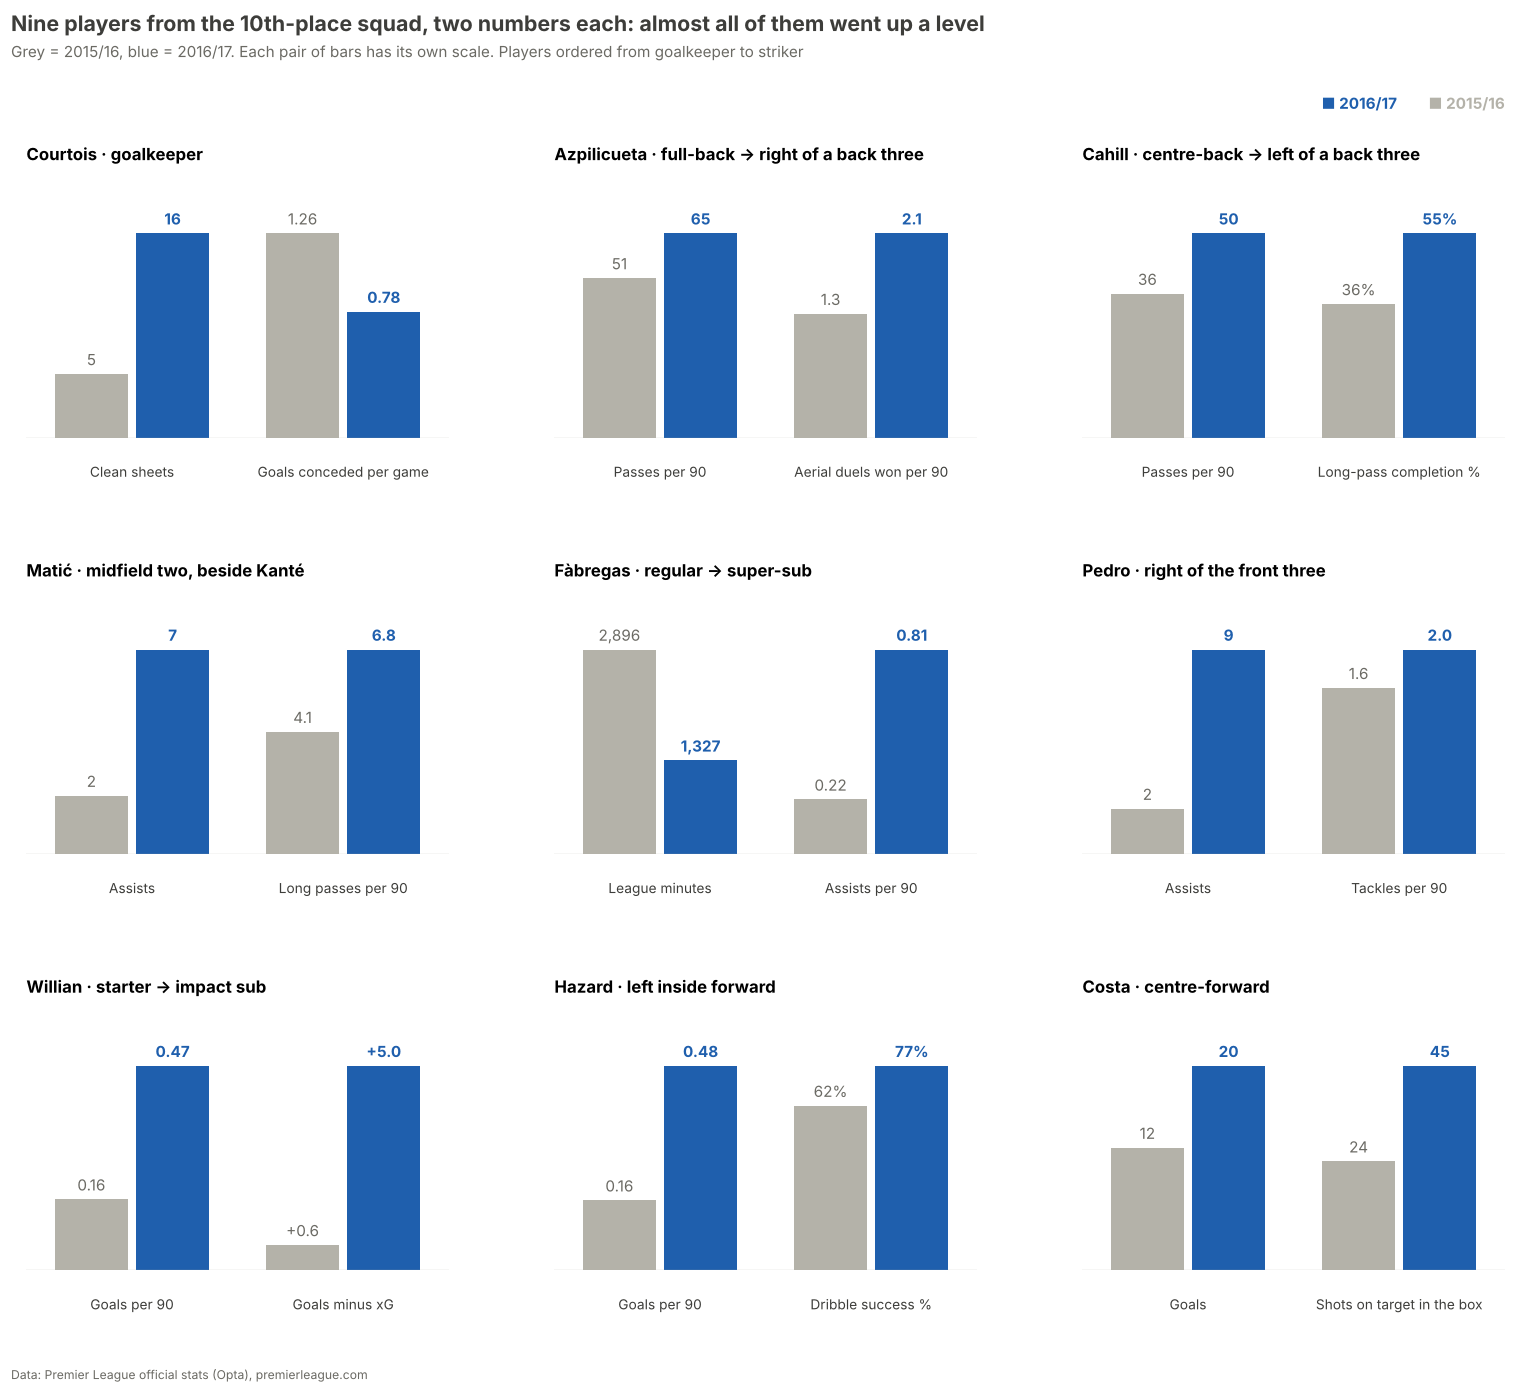

In [3]:
def p90(key, col):
    return P.loc[key, col] / P.loc[key, "Minutes Played"] * 90

def two(name, season):
    return f"{name}@{2015 if season == 15 else 2016}"

# (player, title, [(label, function returning the value for a season key, format)])
CARDS = [
    ("courtois", "Courtois · goalkeeper",
     [("Clean sheets", lambda k: P.loc[k, "Clean Sheets"], "{:.0f}"),
      ("Goals conceded per game", lambda k: P.loc[k, "Goals Conceded"] / P.loc[k, "Appearances"], "{:.2f}")]),
    ("azpilicueta", "Azpilicueta · full-back → right of a back three",
     [("Passes per 90", lambda k: p90(k, "Passes (Completed %)"), "{:.0f}"),
      ("Aerial duels won per 90", lambda k: p90(k, "Aerial Duels Won"), "{:.1f}")]),
    ("cahill", "Cahill · centre-back → left of a back three",
     [("Passes per 90", lambda k: p90(k, "Passes (Completed %)"), "{:.0f}"),
      ("Long-pass completion %", lambda k: P.loc[k, "Long Passes (Completed %) %"], "{:.0f}%")]),
    ("matic", "Matić · midfield two, beside Kanté",
     [("Assists", lambda k: P.loc[k, "Assists"], "{:.0f}"),
      ("Long passes per 90", lambda k: p90(k, "Long Passes (Completed %)"), "{:.1f}")]),
    ("fabregas", "Fàbregas · regular → super-sub",
     [("League minutes", lambda k: P.loc[k, "Minutes Played"], "{:,.0f}"),
      ("Assists per 90", lambda k: p90(k, "Assists"), "{:.2f}")]),
    ("pedro", "Pedro · right of the front three",
     [("Assists", lambda k: P.loc[k, "Assists"], "{:.0f}"),
      ("Tackles per 90", lambda k: p90(k, "Total Tackles"), "{:.1f}")]),
    ("willian", "Willian · starter → impact sub",
     [("Goals per 90", lambda k: p90(k, "Goals"), "{:.2f}"),
      ("Goals minus xG", lambda k: P.loc[k, "Goals"] - P.loc[k, "XG"], "{:+.1f}")]),
    ("hazard", "Hazard · left inside forward",
     [("Goals per 90", lambda k: p90(k, "Goals"), "{:.2f}"),
      ("Dribble success %", lambda k: P.loc[k, "Dribbles (Completed %) %"], "{:.0f}%")]),
    ("costa", "Costa · centre-forward",
     [("Goals", lambda k: P.loc[k, "Goals"], "{:.0f}"),
      ("Shots on target in the box", lambda k: P.loc[k, "Shots On Target Inside the Box"], "{:.0f}")]),
]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
fig.subplots_adjust(hspace=0.55, wspace=0.25, top=0.95, bottom=0.04, left=0.02, right=0.98)
for ax, (key, title, stats) in zip(axes.flat, CARDS):
    xs, labels = [], []
    for j, (lab, fn, fmt) in enumerate(stats):
        a, b = fn(f"{key}@2015"), fn(f"{key}@2016")
        top = max(a, b) * 1.25
        # each stat gets its own scale: normalise to its own max so both fit one panel
        x0 = j * 2.6
        ax.bar(x0, a / top, width=0.9, color=GREY)
        ax.bar(x0 + 1, b / top, width=0.9, color=BLUE)
        ax.text(x0, a / top + 0.02, fmt.format(a), ha="center", va="bottom", fontsize=10, color=MUTED)
        ax.text(x0 + 1, b / top + 0.02, fmt.format(b), ha="center", va="bottom", fontsize=10, color=BLUE, fontweight="bold")
        ax.text(x0 + 0.5, -0.1, lab, ha="center", va="top", fontsize=9, color=DARK)
    ax.set_xlim(-0.8, 4.4)
    ax.set_ylim(0, 1.05)
    ax.axis("off")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_title(title, fontsize=11, loc="left")
fig.text(0.98, 1.0, "■ 2015/16", ha="right", color=GREY, fontsize=10, fontweight="bold")
fig.text(0.91, 1.0, "■ 2016/17", ha="right", color=BLUE, fontsize=10, fontweight="bold")
titles(fig, "Nine players from the 10th-place squad, two numbers each: almost all of them went up a level",
       "Grey = 2015/16, blue = 2016/17. Each pair of bars has its own scale. Players ordered from goalkeeper to striker",
       SRC_PL)
fig.savefig(FIGS / "20_returning_player_cards.png")

## 2. Hazard and Costa: where they shot from

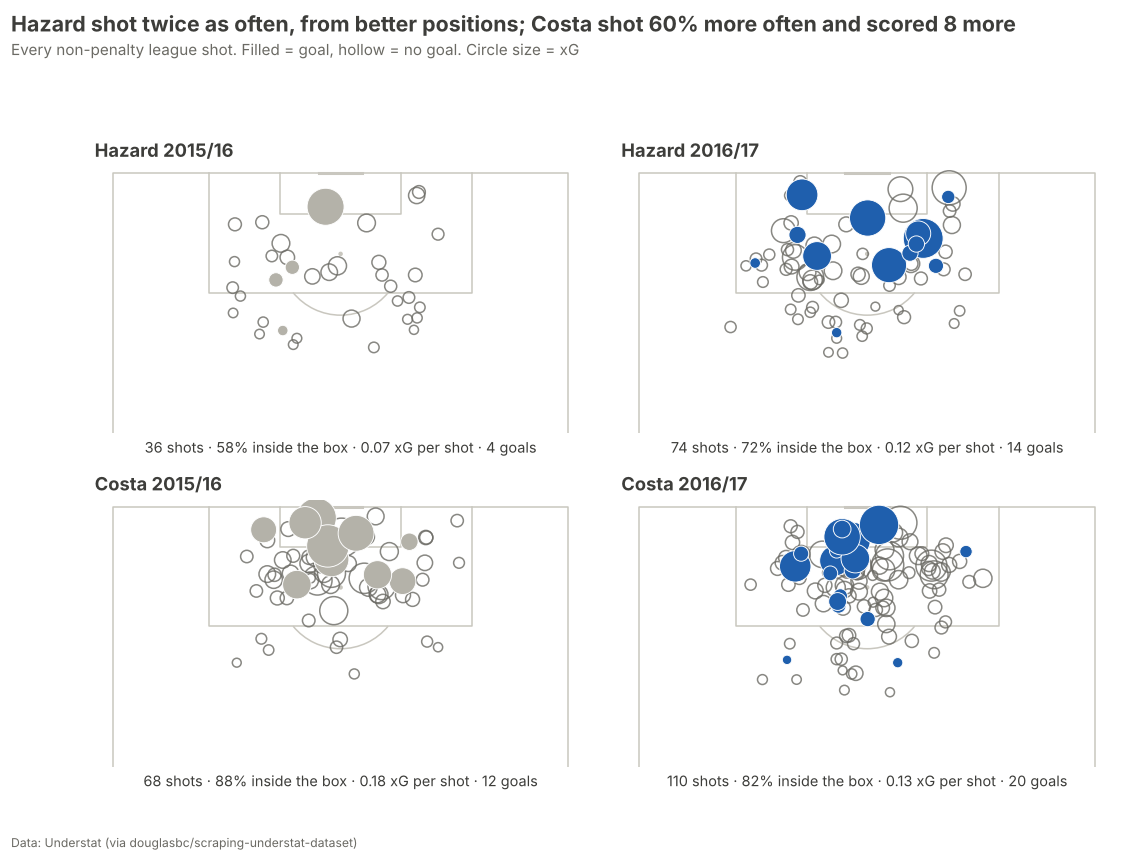

In [4]:
from mplsoccer import VerticalPitch

pitch = VerticalPitch(pitch_type="opta", half=True, pitch_color="white", line_color="#C9C7BF", linewidth=1)
fig, axes = pitch.draw(nrows=2, ncols=2, figsize=(11, 6.6))
fig.subplots_adjust(top=0.95, bottom=0.03, left=0.02, right=0.98, hspace=0.3, wspace=0.06)
for r, name in enumerate(["Eden Hazard", "Diego Costa"]):
    for c, season in enumerate(["15-16", "16-17"]):
        ax = axes[r, c]
        s = load_shots(season)
        d = s[(s.player == name) & (s.team == CHE) & (s.situation != "Penalty")]
        miss, goal = d[~d.goal], d[d.goal]
        pitch.scatter(miss.X * 100, miss.Y * 100, s=miss.xG * 900 + 20, ax=ax, facecolor="none", edgecolor=MUTED, lw=1, alpha=0.8)
        pitch.scatter(goal.X * 100, goal.Y * 100, s=goal.xG * 900 + 20, ax=ax, color=BLUE if season == "16-17" else GREY,
                      edgecolor="white", lw=0.6, zorder=3)
        box = (d.X >= 0.83) & (d.Y.between(0.21, 0.79))
        yr = "2015/16" if season == "15-16" else "2016/17"
        ax.set_title(f"{name.split()[-1]} {yr}", fontsize=12, fontweight="bold", loc="left", color=DARK)
        ax.set_ylim(63, 101)
        ax.text(0.5, -0.02, f"{len(d)} shots · {box.mean():.0%} inside the box · {d.xG.mean():.2f} xG per shot · {len(goal)} goals",
                ha="center", va="top", fontsize=9.5, color=DARK, transform=ax.transAxes)
titles(fig, "Hazard shot twice as often, from better positions; Costa shot 60% more often and scored 8 more",
       "Every non-penalty league shot. Filled = goal, hollow = no goal. Circle size = xG",
       SRC_U)
fig.savefig(FIGS / "21_hazard_costa_shot_maps.png")